In [1]:
import pandas as pd

# Loading data
df = pd.read_csv("weightLogInfo_merged.csv")
df_bmi_usage = pd.read_csv('usage_11_weight_login.csv')

# Cleaning data
df['Date'] = pd.to_datetime(df['Date'],
    format='%m/%d/%Y %I:%M:%S %p')

In [2]:
df_original = df.copy()
df = df.drop_duplicates()

print('Original:', len(df_original))
print('Cleaned:', len(df))
print('Rows dropped:', len(df_original) - len(df))

Original: 33
Cleaned: 33
Rows dropped: 0


In [3]:
df = df.rename(columns={'Id':'user_id',
                   'Date':'date',
                   'WeightKg':'weight_kg',
                   'WeightPounds':'weight_pounds',
                   'Fat':'fat',
                   'BMI':'bmi',
                   'IsManualReport':'is_manual_report',
                   'LogId':'log_id'
                    })

In [4]:
df.describe()


,user_id,date,weight_kg,weight_pounds,fat,bmi,log_id
count,3.300000e+01,33,33.000000,33.000000,2.000000,33.000000,3.300000e+01
mean,6.477156e+09,2016-04-06 16:15:32,73.442425,161.912831,16.000000,25.730909,1.459959e+12
min,1.503960e+09,2016-03-30 23:59:59,53.299999,117.506384,10.000000,21.450001,1.459382e+12
25%,4.702922e+09,2016-04-04 06:53:43,61.700001,136.025217,13.000000,24.100000,1.459753e+12
50%,6.962181e+09,2016-04-06 23:59:59,62.500000,137.788914,16.000000,24.389999,1.459987e+12
75%,8.877689e+09,2016-04-08 23:59:59,85.800003,189.156628,19.000000,25.760000,1.460160e+12
max,8.877689e+09,2016-04-12 23:59:59,129.600006,285.719105,22.000000,46.169998,1.460506e+12
std,2.308888e+09,NaN,16.531127,36.444897,8.485281,4.330387,3.088072e+08


In [6]:
df_bmi_usage = (
    df.groupby('user_id', as_index=False)
    .agg(avg_bmi=('bmi', 'mean'))
)

In [7]:
df_bmi_usage['bmi_category'] = ''

for i in df_bmi_usage.index:
    bmi = df_bmi_usage.loc[i, 'avg_bmi']

    if pd.isna(bmi):
        df_bmi_usage.loc[i, 'bmi_category'] = 'Unknown'

    elif bmi < 18.5:
        df_bmi_usage.loc[i, 'bmi_category'] = 'Underweight'

    elif bmi < 25:
        df_bmi_usage.loc[i, 'bmi_category'] = 'Normal'

    elif bmi < 30:
        df_bmi_usage.loc[i, 'bmi_category'] = 'Overweight'

    else:
        df_bmi_usage.loc[i, 'bmi_category'] = 'Obese'

df_bmi_usage

,user_id,avg_bmi,bmi_category
0,1503960366,22.969999,Normal
1,1927972279,46.169998,Obese
2,2347167796,24.770000,Normal
3,2873212765,21.550000,Normal
4,2891001357,25.030001,Overweight
5,4445114986,35.009998,Obese
6,4558609924,27.139999,Overweight
7,4702921684,26.110001,Overweight
8,6962181067,24.155000,Normal
9,8253242879,29.549999,Overweight


In [10]:
# Set the category order
bmi_order = [
    'Normal',
    'Overweight',
    'Obese'
]

# Set the category colors
bmi_colors = [
    '#FF7F0E',  # Normal
    '#1F77B4',  # Overweight
    '#2CA02C'   # Obese
]

# Count users in each BMI category
bmi_counts = (
    df_bmi_usage['bmi_category']
    .value_counts()
    .reindex(bmi_order, fill_value=0)
)

# Calculate the percentages
total_users = bmi_counts.sum()

bmi_percentages = (
    bmi_counts / total_users * 100
)

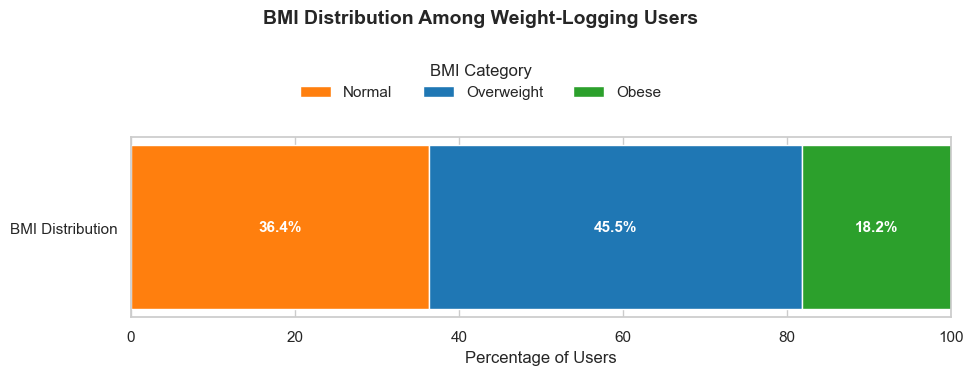

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Increase the figure height
fig, ax = plt.subplots(figsize=(10, 4))

# Set the starting position of the bar
left = 0

for category, percentage, color in zip(
    bmi_order,
    bmi_percentages,
    bmi_colors
):
    ax.barh(
        ['BMI Distribution'],
        percentage,
        left=left,
        color=color,
        label=category
    )

    ax.text(
        left + percentage / 2,
        0,
        f'{percentage:.1f}%',
        ha='center',
        va='center',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

    left += percentage

ax.set_xlabel('Percentage of Users')
ax.set_ylabel('')
ax.set_xlim(0, 100)

# Use fig for the title instead of ax
fig.suptitle(
    'BMI Distribution Among Weight-Logging Users',
    fontsize=14,
    fontweight='bold',
    y=0.97
)

# Place the legend below the title
handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='BMI Category',
    loc='upper center',
    bbox_to_anchor=(0.5, 0.87),
    ncol=3,
    frameon=False
)

# Move the chart area downward
fig.subplots_adjust(
    top=0.65,
    bottom=0.20,
    left=0.15,
    right=0.97
)

plt.show()